# Assignment 2 — Module 2: Artificial Neural Networks

## Practical 9: Model Evaluation Metrics

### Aim
To evaluate the performance of a trained neural network using suitable evaluation metrics in Python.

### Theory
Classification performance cannot be evaluated solely by accuracy, especially with imbalanced classes. The primary metrics are:
- **Accuracy:** $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision:** $\frac{TP}{TP + FP}$ (Quality of positive predictions)
- **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ (Completeness of positive predictions)
- **F1-Score:** $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (Harmonic mean)
- **Confusion Matrix:** Tabular visualization of True Positives, True Negatives, False Positives, and False Negatives.

### Implementation
Training an ANN on Breast Cancer dataset and calculating evaluation metrics:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Load dataset
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Quick ANN model
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=30, batch_size=16, verbose=0)

# Predict on test set
y_pred = (model.predict(X_test) > 0.5).astype(int).flatten()

C:\Users\Shivam\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


### Evaluation Report & Confusion Matrix
Displaying the detailed classification report and plotting the confusion matrix:

=== Classification Report ===
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



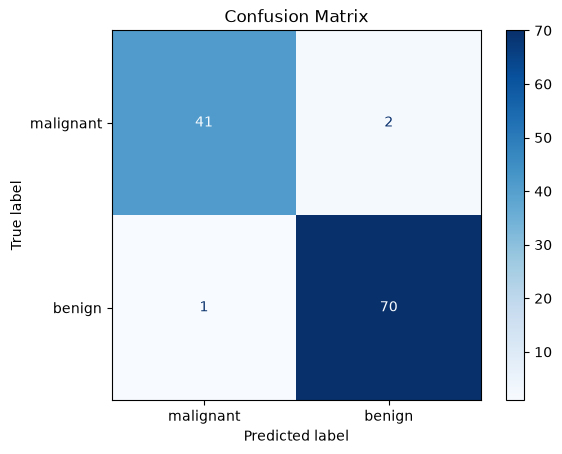

In [2]:
# Print classification report
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.grid(False)
plt.show()

### Observation
- The model achieved high precision, recall, and F1-score across both malignant and benign classes.
- The confusion matrix clearly highlights the true positives, false positives, true negatives, and false negatives.

### Conclusion
Evaluated the performance of a neural network using accuracy, precision, recall, F1-score, and confusion matrix using scikit-learn in Python.